# Files and hyperspectral data

This notebook starts from a CSV file containing a 1 nm spectrum. O25 corrects the complete spectrum. BH4 uncertainty is available only at the 12 matched OLCI bands.

A `NaN` uncertainty outside those bands means **uncertainty is not provided**, not zero uncertainty. Version 0.2 does not interpolate BH4 uncertainty spectrally.


In [2]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np

# Locate the O25 repository automatically.
here = Path.cwd().resolve()
candidates = [here, *here.parents]

# Also consider the common case where Jupyter starts one folder above O25.
candidates.extend(
    folder / "O25"
    for folder in [here, *here.parents]
)

repository = next(
    (
        folder
        for folder in candidates
        if (folder / "o25" / "__init__.py").is_file()
        and (folder / "examples" / "data").is_dir()
    ),
    None,
)

if repository is None:
    raise RuntimeError(
        "The O25 repository could not be located automatically. "
        "Keep this notebook inside the downloaded O25 repository."
    )

# Make the local O25 package available without installing it.
if str(repository) not in sys.path:
    sys.path.insert(0, str(repository))

import o25


data_file = (
    repository
    / "examples"
    / "data"
    / "hyperspectral_spectrum.csv"
)

data = np.loadtxt(
    data_file,
    delimiter=",",
    skiprows=1,
)

wl = data[:, 0]
Rrs = data[:, 1]

print("O25 is ready.")
print("Spectrum loaded:", data_file.name)
print("Number of wavelengths:", wl.size)


O25 is ready.
Spectrum loaded: hyperspectral_spectrum.csv
Number of wavelengths: 451


## Apply O25

The source geometry is `(30, 20, 120)` degrees. The omitted target defaults to `(0, 0, 0)`.


In [3]:
r = o25.correct(wl, Rrs, g0=(30, 20, 120))
print("Input wavelengths:", wl.size)
print("Bands with BH4 uncertainty:", int(r.uncertainty_mask.sum()))
print(r.uncertainty_message)


Input wavelengths: 451
Bands with BH4 uncertainty: 12
BH4 uncertainty at p=0.68 is provided at the 12 matched OLCI bands. 439 other wavelength(s) are NaN; spectral interpolation is not applied.


## Two-panel figure

The upper panel shows the full input and corrected spectra. The lower panel uses error bars only at wavelengths where BH4 is calibrated. The plot deliberately avoids a continuous uncertainty envelope across uncalibrated wavelengths.


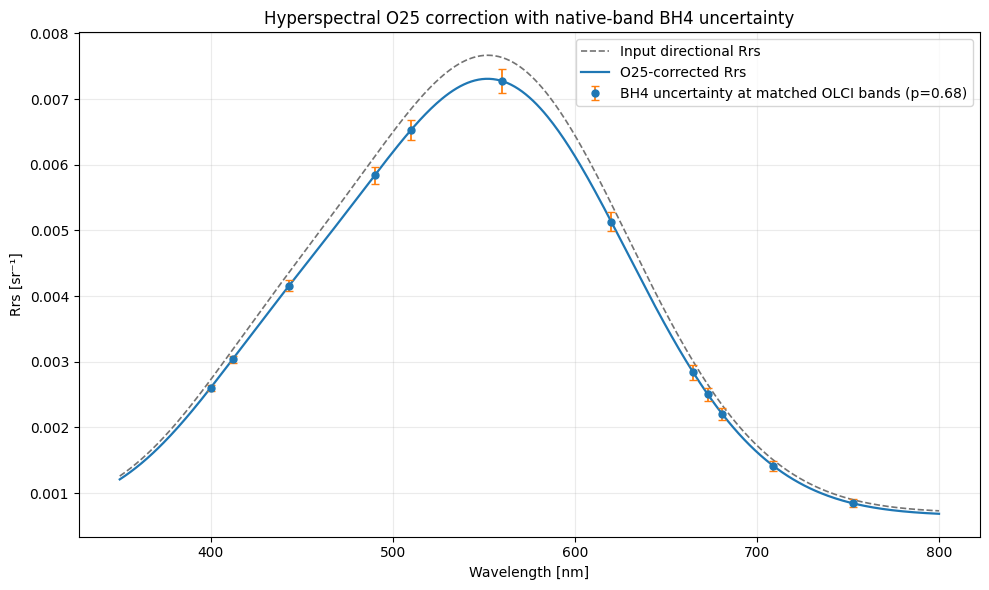

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))

# Original directional spectrum
ax.plot(
    wl,
    Rrs,
    "--",
    linewidth=1.2,
    color="0.45",
    label="Input directional Rrs",
)

# Corrected hyperspectral spectrum
ax.plot(
    wl,
    r.Rrs,
    "-",
    linewidth=1.6,
    color="C0",
    label="O25-corrected Rrs",
)

# BH4 uncertainty only at the 12 matched OLCI bands
m = r.uncertainty_mask

ax.errorbar(
    wl[m],
    r.Rrs[m],
    yerr=r.u[m],
    fmt="o",
    color="C0",
    ecolor="C1",
    markersize=5,
    elinewidth=1.3,
    capsize=3,
    label=f"BH4 uncertainty at matched OLCI bands (p={r.p:g})",
)

ax.set_xlabel("Wavelength [nm]")
ax.set_ylabel("Rrs [sr⁻¹]")
ax.set_title(
    "Hyperspectral O25 correction with native-band BH4 uncertainty"
)
ax.grid(True, alpha=0.25)
ax.legend()
fig.tight_layout()

plt.show()

## Inspect and save availability explicitly

The `uncertainty_available` column makes the distinction between unavailable and finite uncertainty easy to preserve in other software.


In [ ]:
output = np.column_stack((wl, Rrs, r.Rrs, r.u, r.uncertainty_mask.astype(int)))
out_file = data_file.with_name("hyperspectral_result.csv")
np.savetxt(out_file, output, delimiter=",",
           header="wavelength_nm,Rrs_input,Rrs_corrected,uncertainty,uncertainty_available",
           comments="")
print("Saved:", out_file)


## Correction to another target geometry

O25 can correct between arbitrary geometries. BH4 is currently valid only when the target is `(0, 0, 0)`, so uncertainty is unavailable in the following calculation even though corrected Rrs is still returned.


In [6]:
r_other = o25.correct(wl, Rrs, g0=(30,20,120), g1=(40,10,75))
print(r_other.uncertainty_status)
print(r_other.uncertainty_message)
print("Corrected spectrum available:", r_other.Rrs.shape)


unsupported_target_geometry
BH4 is unavailable because its current target geometry must be (0, 0, 0). O25 can still correct to the requested target.
Corrected spectrum available: (451,)
